<a href="https://colab.research.google.com/github/lovelace143/data-viz-classwork/blob/main/DATA300_1113.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import folium
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
GasData = pd.read_excel("ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions")
GasData.columns = GasData.iloc[2]
GasData = GasData.iloc[3:]
GasData.reset_index(drop=True, inplace=True)
emmission_cols = GasData.columns[13:26]
GasData[emmission_cols] = GasData[emmission_cols].apply(pd.to_numeric, errors='coerce')

In [4]:
GasData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    object 
 1   FRS Id                                                                  193 non-null    object 
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [5]:
GasData = GasData.fillna(GasData.mean(numeric_only=True))

In [6]:
totalOverTime = pd.Series(GasData.iloc[:, 13:26].sum(axis=0))

In [7]:
cols = totalOverTime.index
#get the column names from the totalOverTime series' index before we change the index

In [8]:
totalOverTime.index = ['2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011']
totalOverTime = totalOverTime.iloc[::-1]

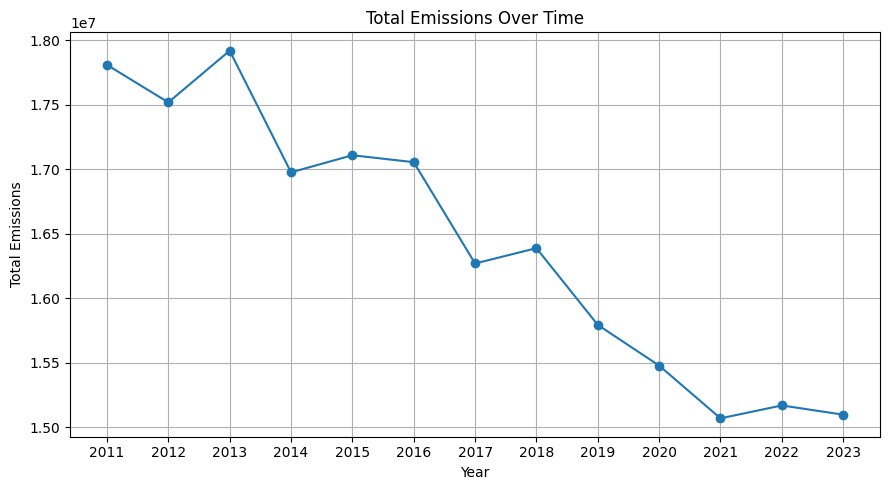

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(totalOverTime, marker='o')
plt.xlabel('Year')
plt.ylabel('Total Emissions')
plt.title('Total Emissions Over Time')
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
cols = pd.array(cols)
cols = cols[::-1]
print(cols) #double-checking we're fine

<NumpyExtensionArray>
['2011 Total reported direct emissions from Local Distribution Companies',
 '2012 Total reported direct emissions from Local Distribution Companies',
 '2013 Total reported direct emissions from Local Distribution Companies',
 '2014 Total reported direct emissions from Local Distribution Companies',
 '2015 Total reported direct emissions from Local Distribution Companies',
 '2016 Total reported direct emissions from Local Distribution Companies',
 '2017 Total reported direct emissions from Local Distribution Companies',
 '2018 Total reported direct emissions from Local Distribution Companies',
 '2019 Total reported direct emissions from Local Distribution Companies',
 '2020 Total reported direct emissions from Local Distribution Companies',
 '2021 Total reported direct emissions from Local Distribution Companies',
 '2022 Total reported direct emissions from Local Distribution Companies',
 '2023 Total reported direct emissions from Local Distribution Companies']
Len

In [11]:
GasData["Total_Emissions_All_Years"] = GasData[cols].sum(axis=1)
print(GasData["Total_Emissions_All_Years"])

0      1.054888e+06
1      1.827507e+05
2      5.211835e+05
3      4.683887e+05
4      2.217845e+06
           ...     
203    8.840537e+05
204    4.309091e+05
205    2.617755e+05
206    4.895121e+05
207    8.091863e+05
Name: Total_Emissions_All_Years, Length: 208, dtype: float64


In [12]:
state_emissions = GasData.groupby("State where Emissions Occur")["Total_Emissions_All_Years"]

state_emissions = GasData.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum()

state_emissions = GasData.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum().reset_index()
state_emissions = state_emissions.sort_values(by="Total_Emissions_All_Years", ascending=False)
#print(state_emissions)

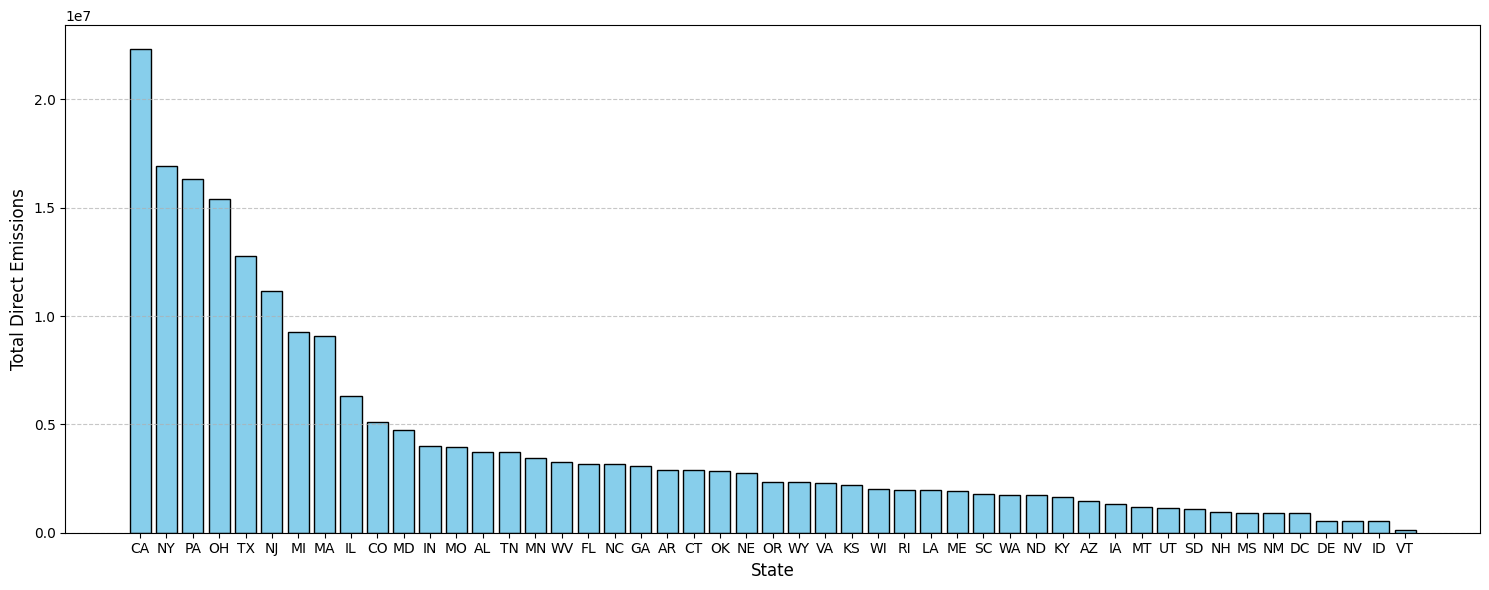

In [13]:
plt.figure(figsize=(15,6))
plt.bar(state_emissions["State where Emissions Occur"], state_emissions["Total_Emissions_All_Years"], color="skyblue", edgecolor="black")

plt.xlabel("State", fontsize=12)
plt.ylabel("Total Direct Emissions", fontsize=12)
plt.grid(axis="y",linestyle='--',alpha=0.7)

plt.tight_layout()
plt.show()

In [20]:
pipelines = pd.read_excel("ghgp_data_by_year_2023.xlsx", sheet_name="Transmission Pipelines")
pipelines.columns = pipelines.iloc[2]
pipelines = pipelines.iloc[3:]
pipelines.reset_index(drop=True, inplace=True)
transmission_emmission_cols = pipelines.columns[13:21]
pipelines[transmission_emmission_cols] = pipelines[transmission_emmission_cols].apply(pd.to_numeric, errors='coerce')

In [22]:
pipelines = pipelines.fillna(pipelines.mean(numeric_only=True))

In [23]:
pipelines.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 21 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   Facility Id                                                       240 non-null    object 
 1   FRS Id                                                            196 non-null    object 
 2   Facility Name                                                     240 non-null    object 
 3   State where Emissions Occur                                       240 non-null    object 
 4   Reported City                                                     240 non-null    object 
 5   Reported State                                                    240 non-null    object 
 6   Reported Zip Code                                                 240 non-null    object 
 7   Reported Address                   

In [24]:
transm_pipelines_arr = pipelines.to_numpy()

emms_only = transm_pipelines_arr[:, 13:].astype(float)

column_sums = np.sum(emms_only, axis=0)
print(column_sums)
column_sums_TP = np.flip(column_sums)
print(column_sums_TP)

[2241411.75660424 3147012.0921021  3561152.33187802 4576106.48890702
 4210325.10517546 4663700.75416219 4499181.65942383 5660412.25834151]
[5660412.25834151 4499181.65942383 4663700.75416219 4210325.10517546
 4576106.48890702 3561152.33187802 3147012.0921021  2241411.75660424]


Transmission Pipeline 32559302.446594384
Line Distribution 213646494.5967785


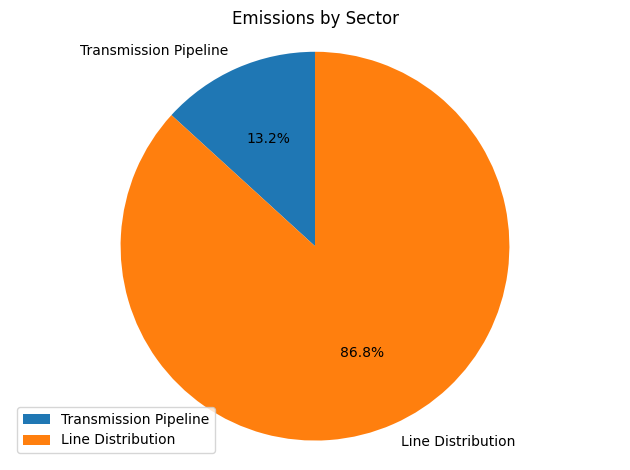

In [35]:
transm_total = np.sum(column_sums_TP)
column_sums_LDC = GasData["Total_Emissions_All_Years"]
dist_total = np.sum(column_sums_LDC)

print("Transmission Pipeline", transm_total)
print("Line Distribution", dist_total)

sector_emms ={
    "Transmission Pipeline": transm_total,
    "Line Distribution": dist_total
}

plt.pie(sector_emms.values(), labels=sector_emms.keys(), autopct='%1.1f%%', startangle=90)
plt.legend()
plt.title("Emissions by Sector")
plt.axis('equal')
plt.tight_layout()
plt.show()